In [2]:
# Problem 1: Distinct (Codility Lesson 6 - Sorting)

def solution(A):
    N = len(A)

    if N == 0:
        return 0

    A = sorted(A)

    count = 1

    for i in range(1, N):
        if A[i] != A[i - 1]:
            count = count + 1

    return count


# Test with the examples
if __name__ == "__main__":
    print(solution([2, 1, 1, 2, 3, 1]))
    print(solution([]))
    print(solution([5, 5, 5]))

3
0
1


In [3]:
# Problem 2: MaxProductOfThree (Codility Lesson 6 - Sorting)

def solution(A):
    N = len(A)

    A = sorted(A)

    # Option 1: the three largest values
    product1 = A[N - 1] * A[N - 2] * A[N - 3]

    # Option 2: the two smallest values (two negatives make a positive)
    # multiplied by the largest value
    product2 = A[0] * A[1] * A[N - 1]

    if product1 > product2:
        return product1
    else:
        return product2


# Test with the examples
if __name__ == "__main__":
    print(solution([-3, 1, 2, -2, 5, 6]))
    print(solution([-5, -6, 1, 2, 3]))
    print(solution([-1, -2, -3, -4]))

60
90
-6


In [4]:
# Problem 3: Triangle (Codility Lesson 6 - Sorting)

def solution(A):
    N = len(A)

    # Sort the array from smallest to largest
    A = sorted(A)

    # Check every group of three neighbours.
    # For sorted values x <= y <= z, we only need to check x + y > z.
    for i in range(N - 2):
        # Zero or negative values can never be triangle sides
        if A[i] > 0 and A[i] + A[i + 1] > A[i + 2]:
            return 1

    # No triangle was found
    return 0


# Test with the examples
if __name__ == "__main__":
    print(solution([10, 2, 5, 1, 8, 20]))
    print(solution([10, 50, 5, 1]))
    print(solution([]))

1
0
0


In [5]:
# Problem 4: CountTriangles (Codility Lesson 15 - Caterpillar method)
def solution(A):
    n = len(A)

    # Sort the array from smallest to largest
    arr = sorted(A)
    count = 0

    for k in range(n - 1, 1, -1):
        left = 0
        right = k - 1

        # Move two pointers towards each other
        while left < right:
            if arr[left] + arr[right] > arr[k]:

                count = count + (right - left)
                right = right - 1
            else:
                # The sum is too small, so try a bigger left value
                left = left + 1

    return count

# Test with the examples
if __name__ == "__main__":
    print(solution([10, 2, 5, 1, 8, 12]))
    print(solution([]))
    print(solution([1, 1, 1]))

4
0
1


In [6]:
# Problem 5: NailingPlanks (Codility Lesson 14 - Binary search algorithm)

def all_nailed(A, B, C, J):
    N = len(A)
    M = len(C)
    max_pos = 2 * M

    marked = [0] * (max_pos + 1)
    for i in range(J):
        marked[C[i]] = 1
    # Prefix sums: prefix[p] = number of nails at or before position p
    prefix = [0] * (max_pos + 1)
    for p in range(1, max_pos + 1):
        prefix[p] = prefix[p - 1] + marked[p]

    # A plank [A[k], B[k]] is nailed if at least one nail is inside it
    for k in range(N):
        if prefix[B[k]] - prefix[A[k] - 1] == 0:
            return False

    return True


def solution(A, B, C):
    low = 1
    high = len(C)
    answer = -1

    # Binary search for the smallest number of nails that works
    while low <= high:
        mid = (low + high) // 2
        if all_nailed(A, B, C, mid):
            answer = mid
            high = mid - 1
        else:
            low = mid + 1
    return answer


# Test with the examples
if __name__ == "__main__":
    print(solution([1, 4, 5, 8], [4, 5, 9, 10], [4, 6, 7, 10, 2]))
    print(solution([1], [1], [2]))
    print(solution([2], [2], [2]))

4
-1
1


In [7]:
!pip install PyMuPDF

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 48.2 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 117.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [PyMuPDF]


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving FUNCTION solution (A).pdf to FUNCTION solution (A) (6).pdf


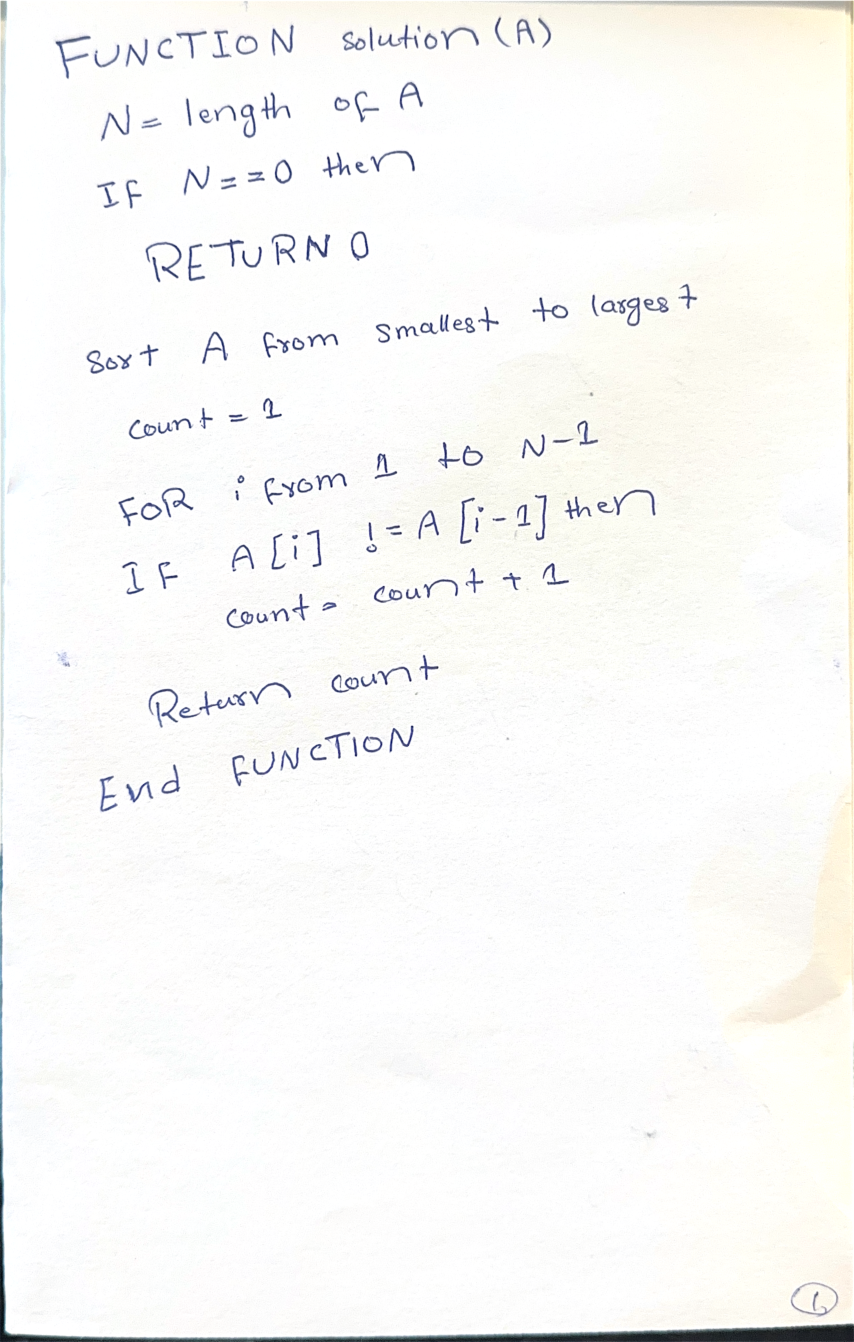

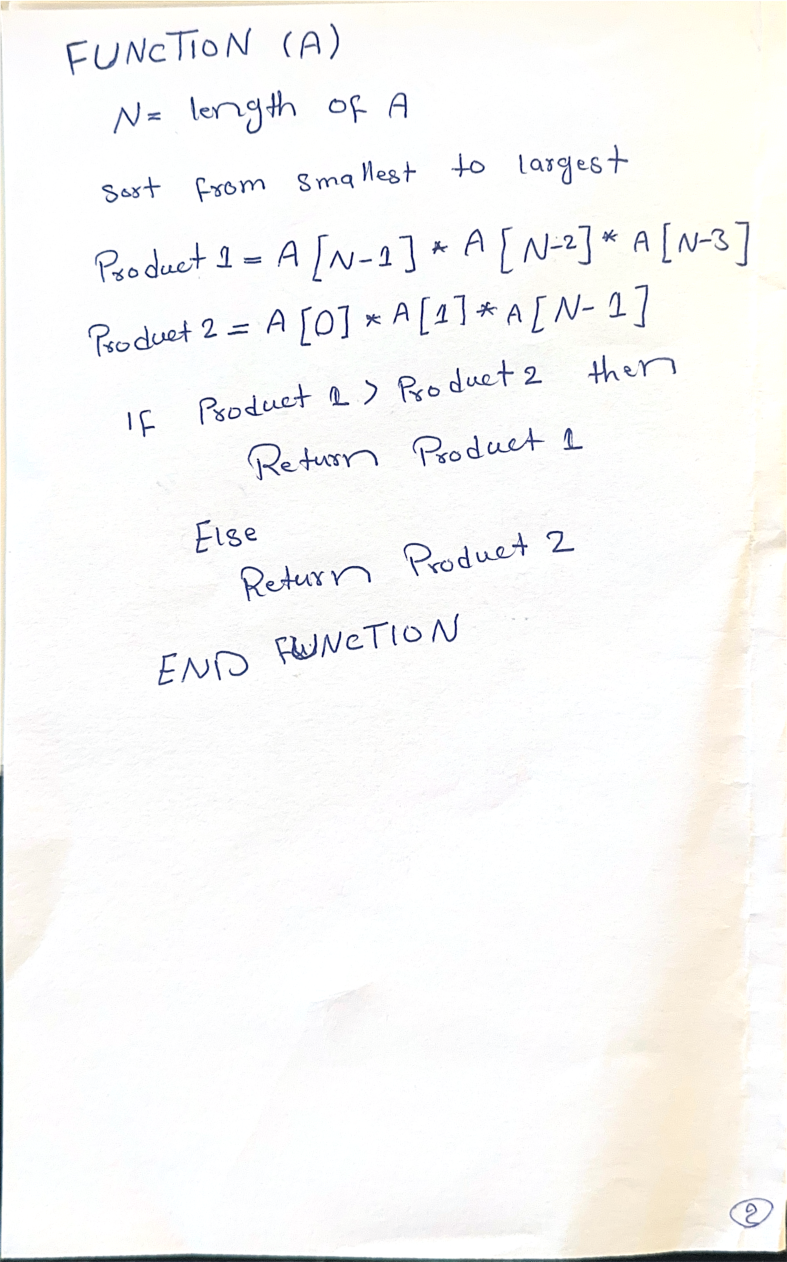

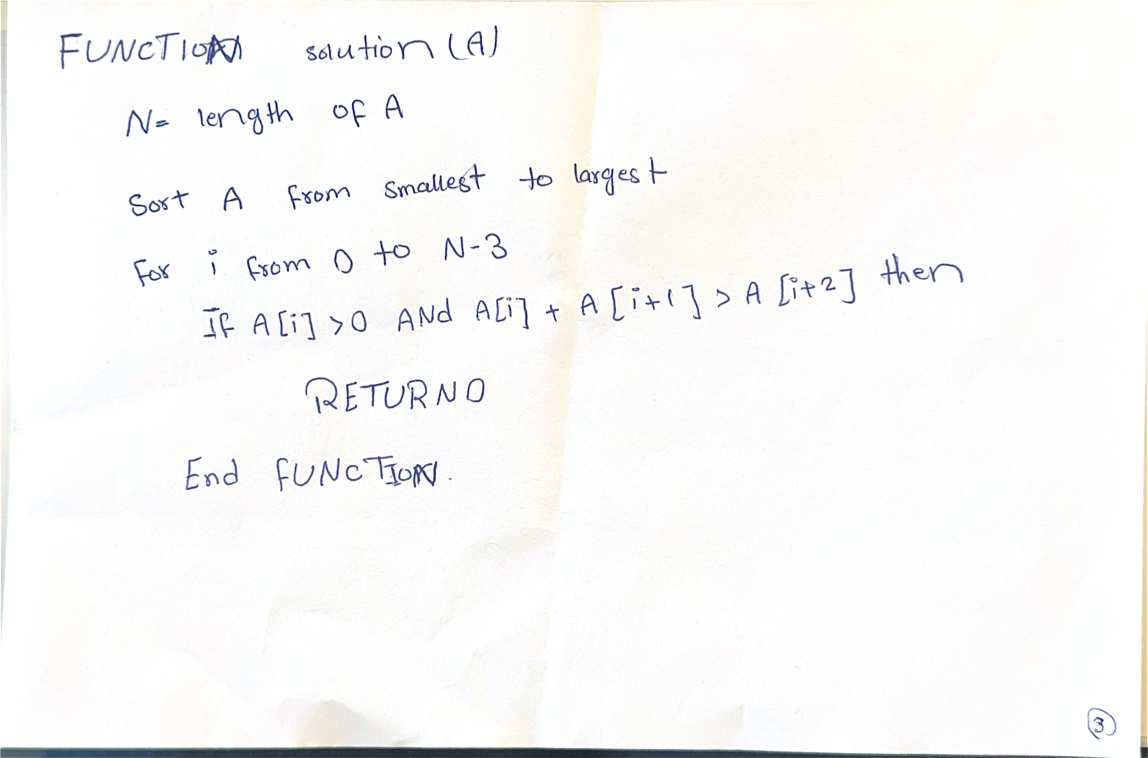

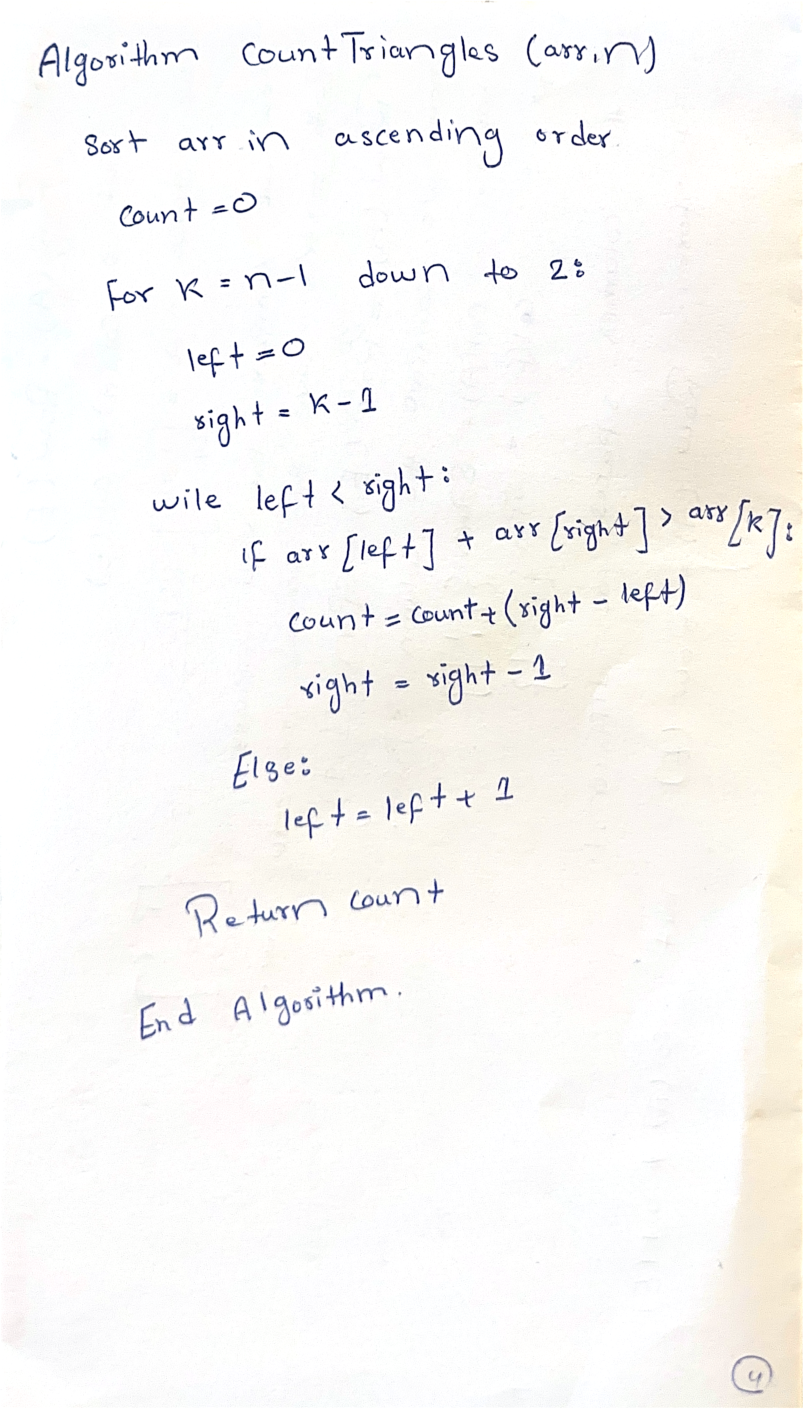

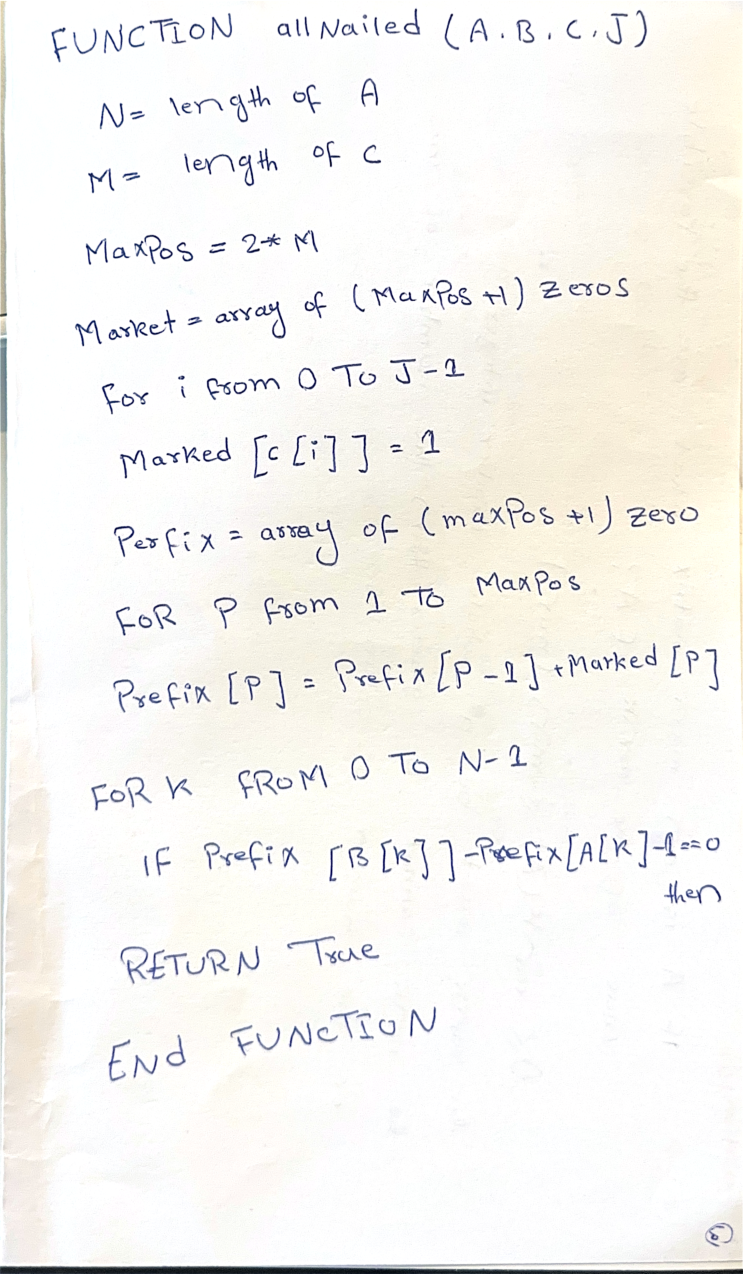

In [1]:
from google.colab import files
import fitz
from PIL import Image
from IPython.display import display
from io import BytesIO

uploaded = files.upload()

for name, data in uploaded.items():
    pdf = fitz.open(stream=data, filetype="pdf")
    for page in pdf:
        pix = page.get_pixmap(matrix=fitz.Matrix(0.5, 0.5))
        display(Image.open(BytesIO(pix.tobytes("png"))))